## Cross-reference TRIM21 IP-MS experimental results with NUP98 MaSIF-mimicry results

**Background:**
- PLRX-93936 (PLRX herein) and BMS-21662 (BMS herein) are TRIM21-based molecular degraders that mediate TRIM21-NUP98 interaction, leading to NUM98 degradation
- We have a cryoEM structure of TRIM21-PLRX-NUP98 ternary structure of PLRX-mediated interaction
- We previously used this cryoEM structure as query model to run MaSIF-mimicry against a database of TED human protein AlphaFold domains, in order to predict 
other protein domains in the human proteome with similar surface features to the NUP98's TRIM21-PLRX binding site, hoping to find other substrates of TRIM21-PLRX.
    - The MaSIF-mimicry score and various postprocessing metrics to evaluate the biological and structural sensibility of the alphafold domain models are stored 
    as `data/NUP98_domain_library_260630/021structure_C_mimicry_postprocessed.csv`
    - The `021structure_C_mimicry_postprocessed.csv` has been filtered by `data/NUP98_domain_library_260630/021structure_C_mimicry_domain-library-filters_260630.json` 
    to create a shortlist of top candidates with both high MaSIF scroe and structural and biological sensibility to test in cells
- We have recently performed IP-MS using FLAG-TRIM21 as bait, and compare the enrichment of PLRX or BMS-dependent binders to FLAG-TRIM21 immobilized on anti-FLAG
M2 beads. 
- TRIM21 is a dimer, and it is known to have an endogenous function to target oligomeric complexes.
- The hypothesis is that proteins that meet one or more of the following criteria are more likely to be real molecular glue substrates:
    - Having a p-value of <0.05 in IP-MS data (either induced by PLRX or BMS), and has a high logFC
    - Having a high MaSIF-score and cluster_size in `data/NUP98_domain_library_260630/021structure_C_mimicry_postprocessed.csv`
        - Bonus point if the domain are structurally and biologically sensible (i.e. passing filtering criteria defined i `021structure_C_mimicry_domain-library-filters_260630.json`)
    - Known to be an oligomer based on available literature.


**Input data:**
- MaSIF-Mimicry results: Previously ran MaSIF-mimicry results are available from `data/NUP98_domain_library_260630` folder
- TRIM21 IP-MS results available in `data/TRIM21_IP-MS` folder:
    - `TRIM21-FL_results.csv`: FL FLAG-TRIM21 was expressed in HEK293T cells treated with either PLRX/BMS compound or DMSO, before FLAG-IP. p-value and logFC compares 
    samples treated with PLRX/BSM vs DMSO (positive logFC means enrichment in compound treated samples). Data from 3 replicates.
    - `TRIM21-fragment_results.csv`: purified recombinant FLAG-TRIM21 receptor domain is immobilzed on anti-FLAG M2 beads as bait, before mixing with HEK293T cell lysate
    treated with PLRX/BMS/DMSO for pulldown. p-value and logFC compares samples treated with PLRX/BSM vs DMSO (positive logFC means enrichment in compound treated samples). Data from 3 replicates. 
    - `data/TRIM21_IP-MS/proteinGroups_TRIM21-FL_1.txt`: metadata about protein ids from the first replicate of TRIM21-FL_results
    - `data/TRIM21_IP-MS/proteinGroups_TRIM21-FL_1.txt`: metadata about protein ids from the 2nd and 3rd replicate of TRIM21-FL_results
    - `data/TRIM21_IP-MS/proteinGroups_TRIM21-fragment_1.txt`: metadata about protein ids from the first replicate of TRIM21-fragment_results
    - `data/TRIM21_IP-MS/proteinGroups_TRIM21-fragment_2.txt`: metadata about protein ids from the 2nd and 3rd replicate of TRIM21-fragment_results
- Oligomeric states of candidate binder proteins: need to investigate what database can we pull this information from, or manually check literature after we triage to
a shortlist of top candidates based on the input data above


**Goal:**
- Cross-reference between different input data sources to find candidate proteins for which we have high confidence that it binds to TRIM21-PLRX/BMS complex
- A protein should be identified by its sequence, not any uniprot_id or identifiers, because different uniprot_ids may have domains with very similar sequences.
MaSIF-mimicry results already have sequence for the domain. IP-MS data's metadata does not contain protein sequence, so we need to make UniProt API calls to get the exact protein sequence, so that we can match each entry in IP-MS results.csv with a protein sequence. Then, we run cd-hit to cluster protein sequences using a high identity threshold
(e.g. 0.98, based on the aligned region of the shorter sequence), so proteins within the same cluster are considered the same protein, even if they have different identifiers in 
different datasets. 
- At every step, plot the data to visualize how top candidates are selected. 

## 1. Load & inspect inputs

Run this notebook with the `MaSIF` conda env as kernel (`cd-hit`, biopython, requests, pandas, matplotlib all live there).

We use `021structure_C_mimicry_postprocessed.csv` (the full, unfiltered set of search hits with postprocessing
metrics) as the base MaSIF-mimicry table rather than the already-filtered/deduped `..._filtered.csv` /
`..._dedup.csv`. Reasoning: per the task markdown, passing the structural/biological filters
(`021structure_C_mimicry_domain-library-filters_260630.json`) is a *bonus point*, not a requirement — a
domain with a high `MaSIF-score`/`cluster_size` that narrowly misses one filter (e.g. `norm_sasa` or
`matched_iface_plddt`) should still be visible as a candidate if IP-MS also supports it. We load the filter
JSON anyway so we can flag "passes full filter set" as one of the evidence columns later.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = REPO_ROOT / "data"
MIMICRY_DIR = DATA_DIR / "NUP98_domain_library_260630"
IPMS_DIR = DATA_DIR / "TRIM21_IP-MS"
assert MIMICRY_DIR.is_dir(), MIMICRY_DIR
assert IPMS_DIR.is_dir(), IPMS_DIR

pd.set_option("display.max_columns", 50)

In [2]:
# --- MaSIF-mimicry side ---
mimicry_df = pd.read_csv(MIMICRY_DIR / "021structure_C_mimicry_postprocessed.csv", low_memory=False)

with open(MIMICRY_DIR / "021structure_C_mimicry_domain-library-filters_260630.json") as fh:
    mimicry_filters = json.load(fh)

print(f"mimicry_df: {mimicry_df.shape[0]} rows, {mimicry_df.shape[1]} cols")
print("mimicry_filters:", mimicry_filters)

key_mimicry_cols = ["P1_id", "uniprot_accn", "gene_name", "domain_seq", "MaSIF-score", "cluster_size"]
print("\nMissingness in key columns:")
print(mimicry_df[key_mimicry_cols].isna().mean().round(3))
mimicry_df[key_mimicry_cols].head()

mimicry_df: 22471 rows, 87 cols
mimicry_filters: {'cluster_size': {'min': 40, 'max': None}, 'cluster_mean_rmsd': {'min': None, 'max': 4}, 'MaSIF-score': {'min': 0.5, 'max': None}, 'matched_iface_plddt': {'min': 80, 'max': None}, 'iface_intracellular_frac': {'min': 0.8, 'max': None}, 'n_P2_source_site': {'min': 7, 'max': None}, 'norm_sasa': {'min': None, 'max': 95}}

Missingness in key columns:
P1_id           0.000
uniprot_accn    0.000
gene_name       0.008
domain_seq      0.000
MaSIF-score     0.000
cluster_size    0.000
dtype: float64


,P1_id,uniprot_accn,gene_name,domain_seq,MaSIF-score,cluster_size
0,A0A2R8Y422-F1-TED01_A,A0A2R8Y422,NaN,IFVKTLMGKTITLEVELSDTIDNVKAKIQDKEGIPPDQQRLIFAGK...,0.453158,2.0
1,A6NKT7-F1-TED06_A,A6NKT7,RGPD3,TKSADHLNGLLREIEATNAVLMEQIKLLKSEIRRLERNQEQEVSAA...,0.508498,19.0
2,O00370-F1-TED04_A,O00370,NaN,IKKWAKDMNRHFSKEDIYAAKKHMKKCSSSLAIREMQIKTTMRYHL...,0.534742,34.0
3,O15063-F1-TED02_A,O15063,GARRE1,RGCDGCLAGIEVQQLFCSQSAAIPEHQLKELNIKIDSALQAYKIAL...,0.518404,60.0
4,O43683-F1-TED02_A,O43683,BUB1,DKLIFKLLSGLSKPVSSYPNTFEWQCKLPAIKPKTEFQLGSKLVYV...,0.474975,16.0


In [3]:
# --- IP-MS side ---
ipms_results = {
    "FL": pd.read_csv(IPMS_DIR / "TRIM21-FL_results.csv"),
    "fragment": pd.read_csv(IPMS_DIR / "TRIM21-fragment_results.csv"),
}
protein_groups = {
    "FL": [
        pd.read_csv(IPMS_DIR / "proteinGroups_TRIM21-FL_1.txt", sep="\t", low_memory=False),
        pd.read_csv(IPMS_DIR / "proteinGroups_TRIM21-FL_2.txt", sep="\t", low_memory=False),
    ],
    "fragment": [
        pd.read_csv(IPMS_DIR / "proteinGroups_TRIM21-fragment_1.txt", sep="\t", low_memory=False),
        pd.read_csv(IPMS_DIR / "proteinGroups_TRIM21-fragment_2.txt", sep="\t", low_memory=False),
    ],
}

for name, df in ipms_results.items():
    n_dupe_genes = df["Gene names"].duplicated().sum()
    n_multi_gene = df["Gene names"].astype(str).str.contains(";").sum()
    print(
        f"{name}: {len(df)} rows, {df['Gene names'].nunique()} unique Gene names "
        f"({n_dupe_genes} duplicated, {n_multi_gene} compound e.g. 'ABI1;ABI2')"
    )
    print(f"  missing pval_prlx: {df['pval_prlx'].isna().mean():.3f}, missing pval_bms: {df['pval_bms'].isna().mean():.3f}")

for name, dfs in protein_groups.items():
    for i, df in enumerate(dfs, start=1):
        print(
            f"proteinGroups {name} rep{i}: {len(df)} rows, "
            f"{df['Gene names'].isna().sum()} missing Gene names"
        )

ipms_results["FL"].head()

FL: 3745 rows, 3745 unique Gene names (0 duplicated, 230 compound e.g. 'ABI1;ABI2')
  missing pval_prlx: 0.030, missing pval_bms: 0.080
fragment: 4002 rows, 4002 unique Gene names (0 duplicated, 253 compound e.g. 'ABI1;ABI2')
  missing pval_prlx: 0.099, missing pval_bms: 0.092
proteinGroups FL rep1: 2950 rows, 42 missing Gene names
proteinGroups FL rep2: 3379 rows, 70 missing Gene names
proteinGroups fragment rep1: 3513 rows, 51 missing Gene names
proteinGroups fragment rep2: 3334 rows, 59 missing Gene names


,Gene names,LFQ intensity BMS_exp1,LFQ intensity Ctrl_exp1,LFQ intensity DMSO_exp1,LFQ intensity PRLX_exp1,LFQ intensity BMS_01_exp2,LFQ intensity BMS_02_exp2,LFQ intensity CTRL_exp2,LFQ intensity DMSO_01_exp2,LFQ intensity DMSO_02_exp2,LFQ intensity PRLX_01_exp2,LFQ intensity PRLX_02_exp2,pval_prlx,sig_prlx,logFC_prlx,pval_bms,sig_bms,logFC_bms
0,AAAS,0.001651,0.000000,0.001900,0.004137,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.648913,0.187814,1.122515,0.925781,0.033492,-0.203150
1,AAMDC,0.364371,343.586585,1.124508,2.440416,0.791712,1.070307,58.307806,0.881847,1.052942,1.032593,1.152313,0.316488,0.499642,0.596354,0.270942,0.567124,-0.458493
2,AAMP,0.010218,0.544723,0.021053,0.023971,0.011690,0.015483,0.156087,0.006525,0.010385,0.013436,0.016762,0.369140,0.432809,0.512896,0.969147,0.013610,-0.021835
3,AAR2,0.009538,0.000000,0.011604,0.016937,0.039135,0.056869,0.963978,0.041926,0.043124,0.058658,0.069555,0.444245,0.352377,0.586646,0.871825,0.059571,0.126935
4,AARS,0.009329,0.000000,0.017030,0.020144,0.004234,0.006740,0.000000,0.000000,0.004660,0.006323,0.008632,0.537752,0.269418,0.694421,0.934571,0.029388,-0.095313


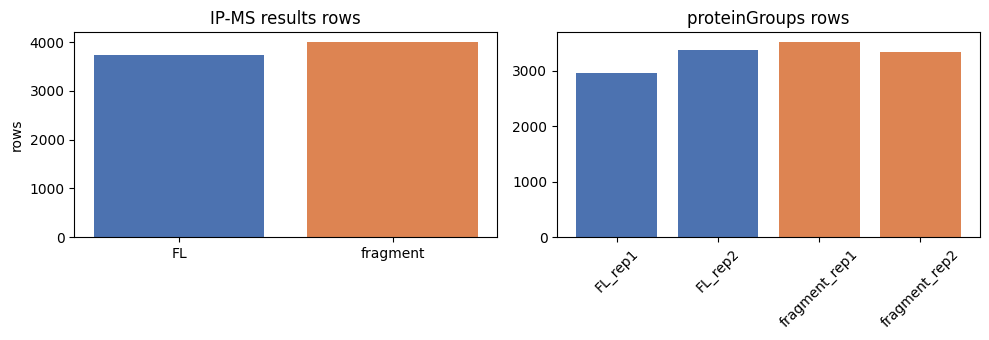

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

axes[0].bar(list(ipms_results.keys()), [len(df) for df in ipms_results.values()], color=["#4C72B0", "#DD8452"])
axes[0].set_title("IP-MS results rows")
axes[0].set_ylabel("rows")

axes[1].bar(
    [f"{name}_rep{i}" for name, dfs in protein_groups.items() for i in (1, 2)],
    [len(df) for dfs in protein_groups.values() for df in dfs],
    color=["#4C72B0", "#4C72B0", "#DD8452", "#DD8452"],
)
axes[1].set_title("proteinGroups rows")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

## 2. Gene name -> UniProt accession(s) join (IP-MS side)

`TRIM21-*_results.csv` only carries MaxQuant `Gene names` (sometimes compound, e.g. `ABI1;ABI2` for
indistinguishable protein groups). To get a sequence we join against the two `proteinGroups_*.txt` replicate
files per dataset on gene symbol, pulling `Majority protein IDs`.

We match at the level of individual gene symbol **tokens** (splitting compound `Gene names` on `;`) rather
than requiring an exact string match of the whole compound field, because MaxQuant's protein-group grouping
can differ slightly between replicate runs (e.g. one replicate resolves `ABI1;ABI2` as a single group, another
splits them) — token-level matching is robust to that. For each result row we take the **union** of
accessions across every proteinGroups row (either replicate) that shares at least one gene-symbol token, and
keep every accession listed rather than guessing a single "canonical" one (isoforms/TrEMBL entries included)
— cd-hit in Section 4 will resolve which one, if any, actually matches a MaSIF domain.

Caveat carried into Section 3: `Majority protein IDs` can contain isoform-suffixed accessions (e.g.
`P46379-2`). UniProt's batch search endpoint indexes canonical accessions only, so we'll fetch the canonical
(base) accession's sequence for these rather than the exact isoform — a reasonable approximation, but worth
knowing if a borderline cd-hit match involves an isoform-heavy gene.

In [5]:
def build_gene_token_map(pg_dfs):
    """Map each individual gene-symbol token -> set of accessions, pooled across proteinGroups dataframes."""
    token_map = {}
    for df in pg_dfs:
        sub = df[["Gene names", "Majority protein IDs"]].dropna(subset=["Gene names", "Majority protein IDs"])
        for gene_field, acc_field in zip(sub["Gene names"], sub["Majority protein IDs"]):
            accessions = [a.strip() for a in str(acc_field).split(";") if a.strip()]
            for token in str(gene_field).split(";"):
                token = token.strip()
                if token:
                    token_map.setdefault(token, set()).update(accessions)
    return token_map


def resolve_accessions(gene_names_field, token_map):
    tokens = [t.strip() for t in str(gene_names_field).split(";") if t.strip()]
    accessions = set()
    for t in tokens:
        accessions.update(token_map.get(t, set()))
    return tokens, sorted(accessions)


gene_accession_maps = {}
for dataset, results_df in ipms_results.items():
    token_map = build_gene_token_map(protein_groups[dataset])
    records = []
    for idx, gene_names in results_df["Gene names"].items():
        tokens, accessions = resolve_accessions(gene_names, token_map)
        records.append(
            {
                "result_row": idx,
                "gene_names": gene_names,
                "n_query_genes": len(tokens),
                "accessions": accessions,
                "n_accessions": len(accessions),
            }
        )
    gmap = pd.DataFrame(records).set_index("result_row")
    gmap["ambiguous_gene"] = gmap["n_query_genes"] > 1
    gmap["unresolved"] = gmap["n_accessions"] == 0
    gene_accession_maps[dataset] = gmap

    n = len(gmap)
    print(
        f"{dataset}: {n} rows -> {gmap['unresolved'].sum()} unresolved (no accession found), "
        f"{gmap['ambiguous_gene'].sum()} ambiguous (compound gene name), "
        f"{(~gmap['unresolved']).sum()} resolved to >=1 accession"
    )

gene_accession_maps["FL"].head()

FL: 3745 rows -> 0 unresolved (no accession found), 230 ambiguous (compound gene name), 3745 resolved to >=1 accession
fragment: 4002 rows -> 0 unresolved (no accession found), 253 ambiguous (compound gene name), 4002 resolved to >=1 accession


,gene_names,n_query_genes,accessions,n_accessions,ambiguous_gene,unresolved
result_row,,,,,,
0,AAAS,1,"[F8VUB6, F8VZ44, H3BU82, Q9NRG9, Q9NRG9-2]",5,False,False
1,AAMDC,1,"[E9PIQ4, E9PNP3, E9PR47, Q9H7C9]",4,False,False
2,AAMP,1,"[C9JEH3, C9JG97, C9JTS3, H7C0R2, Q13685]",5,False,False
3,AAR2,1,"[A0A7P0T8J7, A0A7P0TA70, A2A2Q9, Q9Y312]",4,False,False
4,AARS,1,"[A0A6Q8PF33, A0A6Q8PFK3, A0A6Q8PFY2, A0A6Q8PGB...",12,False,False


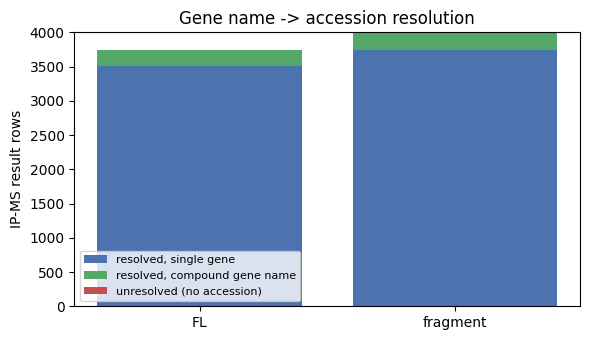

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.5))
datasets = list(gene_accession_maps.keys())
resolved_unambig = [((~m["unresolved"]) & (~m["ambiguous_gene"])).sum() for m in gene_accession_maps.values()]
resolved_ambig = [((~m["unresolved"]) & (m["ambiguous_gene"])).sum() for m in gene_accession_maps.values()]
unresolved = [m["unresolved"].sum() for m in gene_accession_maps.values()]

x = np.arange(len(datasets))
ax.bar(x, resolved_unambig, label="resolved, single gene", color="#4C72B0")
ax.bar(x, resolved_ambig, bottom=resolved_unambig, label="resolved, compound gene name", color="#55A868")
ax.bar(
    x,
    unresolved,
    bottom=np.array(resolved_unambig) + np.array(resolved_ambig),
    label="unresolved (no accession)",
    color="#C44E52",
)
ax.set_xticks(x)
ax.set_xticklabels(datasets)
ax.set_ylabel("IP-MS result rows")
ax.set_title("Gene name -> accession resolution")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [7]:
import re

# Official UniProtKB accession format (6 or 10 chars). MaxQuant `Majority protein IDs` also contains
# non-UniProt tokens (CON__... contaminants, REV__... decoys, and here a custom bait label
# "TRIM21Regina") that must be filtered out *before* batching -- one bad token turns the whole batch's
# query into an HTTP 400 and silently drops every legitimate accession alongside it.
UNIPROT_ACCESSION_RE = re.compile(
    r"^([A-NR-Z][0-9]([A-Z][A-Z0-9]{2}[0-9]){1,2})$|^([OPQ][0-9][A-Z0-9]{3}[0-9])$"
)


def canonical_accession(accession: str) -> str:
    """Strip UniProt isoform suffix, e.g. 'P46379-2' -> 'P46379'."""
    return accession.split("-")[0]


all_accessions_raw = set()
for gmap in gene_accession_maps.values():
    for accs in gmap["accessions"]:
        all_accessions_raw.update(canonical_accession(a) for a in accs)

unique_accessions = sorted(a for a in all_accessions_raw if UNIPROT_ACCESSION_RE.match(a))
non_uniprot_tokens = sorted(a for a in all_accessions_raw if not UNIPROT_ACCESSION_RE.match(a))

print(f"{len(unique_accessions)} unique canonical UniProt accessions to fetch sequences for")
print(f"{len(non_uniprot_tokens)} non-UniProt tokens filtered out (contaminants/decoys/custom labels), e.g.:")
print(non_uniprot_tokens[:10])

15953 unique canonical UniProt accessions to fetch sequences for
51 non-UniProt tokens filtered out (contaminants/decoys/custom labels), e.g.:
['CON__ENSEMBL:ENSBTAP00000007350', 'CON__ENSEMBL:ENSBTAP00000031900', 'CON__H', 'CON__P01030', 'CON__P01966', 'CON__P02533', 'CON__P02538', 'CON__P02676', 'CON__P02768', 'CON__P04259']


## 3. Fetch sequences + subunit info from UniProt

16,004 unique canonical accessions is more than expected (each `Majority protein IDs` entry often lists
5-10 accessions for one gene). We fetch in batches via UniProt's `uniprotkb/stream` endpoint, same
`accession:(A OR B OR ...)` batching pattern as `scripts/bonsai_scripts/python/fetch_fasta_batch.py`, but:
- **one combined JSON call per batch** (`fields=accession,sequence,cc_subunit`) instead of a separate FASTA
  pass and a separate subunit-comment pass — halves the number of network round trips.
- **disk-cached** to `data/TRIM21_IP-MS/uniprot_cache.json`, keyed by accession, so re-running the notebook
  (or picking up after an interruption) never re-fetches an accession we already have.

At ~16k accessions / 100 per batch (~160 requests, 1s polite delay between batches) this takes a few
minutes — still comfortably interactive, no need for the SLURM fallback.

We pull the "Subunit structure" comment (`cc_subunit`) here too, since it's free in the same call — used in
Section 5/6 as a first-pass, heuristic "known oligomer" signal (keyword search for
homodimer/homotrimer/etc.). This is not a substitute for literature curation on the final shortlist, just a
cheap way to not throw away a signal we're already paying for.

In [8]:
import time

import requests

UNIPROT_CACHE_PATH = IPMS_DIR / "uniprot_cache.json"
UNIPROT_BATCH_SIZE = 100
UNIPROT_STREAM_URL = "https://rest.uniprot.org/uniprotkb/stream"


def load_uniprot_cache(path):
    if path.is_file():
        with open(path) as fh:
            return json.load(fh)
    return {}


def save_uniprot_cache(cache, path):
    with open(path, "w") as fh:
        json.dump(cache, fh)


def parse_subunit_text(entry):
    texts = []
    for comment in entry.get("comments", []):
        if comment.get("commentType") == "SUBUNIT":
            texts.extend(t["value"] for t in comment.get("texts", []) if "value" in t)
    return " | ".join(texts)


def fetch_uniprot_batch(accessions, retries=2):
    """Return a list of entries on success (possibly empty), or None if the request itself failed.

    The empty-vs-None distinction matters: an empty list means UniProt answered and knows nothing about
    these accessions (obsolete/merged), which we want to cache as unresolved; None means the network or
    server failed, which must stay uncached so it is retried.
    """
    query = "accession:(" + " OR ".join(accessions) + ")"
    params = {"format": "json", "fields": "accession,sequence,cc_subunit", "query": query}
    for attempt in range(retries + 1):
        try:
            resp = requests.get(UNIPROT_STREAM_URL, params=params, timeout=60)
            resp.raise_for_status()
            return resp.json().get("results", [])
        except Exception as e:
            if attempt == retries:
                print(f"  batch of {len(accessions)} failed after {retries + 1} attempts: {e}")
                return None
            time.sleep(2)

In [9]:
uniprot_cache = load_uniprot_cache(UNIPROT_CACHE_PATH)
to_fetch = [a for a in unique_accessions if a not in uniprot_cache]
print(f"{len(uniprot_cache)} accessions already cached, {len(to_fetch)} left to fetch")

for i in range(0, len(to_fetch), UNIPROT_BATCH_SIZE):
    batch = to_fetch[i : i + UNIPROT_BATCH_SIZE]
    entries = fetch_uniprot_batch(batch)
    if entries is not None:
        for entry in entries:
            acc = entry["primaryAccession"]
            uniprot_cache[acc] = {
                "sequence": entry.get("sequence", {}).get("value"),
                "subunit_text": parse_subunit_text(entry),
            }
        # Request succeeded, so anything UniProt did not return is genuinely obsolete/merged: cache it as
        # unresolved rather than re-requesting it on every future run. Failed requests (None) stay uncached.
        for acc in batch:
            if acc not in uniprot_cache:
                uniprot_cache[acc] = {"sequence": None, "subunit_text": "", "unresolved": True}
    time.sleep(1)
    batch_num = i // UNIPROT_BATCH_SIZE
    if batch_num % 10 == 0:
        save_uniprot_cache(uniprot_cache, UNIPROT_CACHE_PATH)
        print(f"  ... {min(i + UNIPROT_BATCH_SIZE, len(to_fetch))}/{len(to_fetch)} fetched")

save_uniprot_cache(uniprot_cache, UNIPROT_CACHE_PATH)

n_seq = sum(1 for a in unique_accessions if uniprot_cache.get(a, {}).get("sequence"))
n_unresolved = sum(1 for a in unique_accessions if uniprot_cache.get(a, {}).get("unresolved"))
n_retry = sum(1 for a in unique_accessions if a not in uniprot_cache)
print(
    f"Done: {n_seq} accessions with sequence, {n_unresolved} obsolete/merged "
    f"(cached as unresolved, not re-requested), {n_retry} left to retry"
)

15953 accessions already cached, 0 left to fetch
Done: 15951 accessions with sequence, 2 obsolete/merged (cached as unresolved, not re-requested), 0 left to retry


6675/15953 accessions have a Subunit-structure comment
1572/15953 flagged as likely self-oligomeric by keyword heuristic


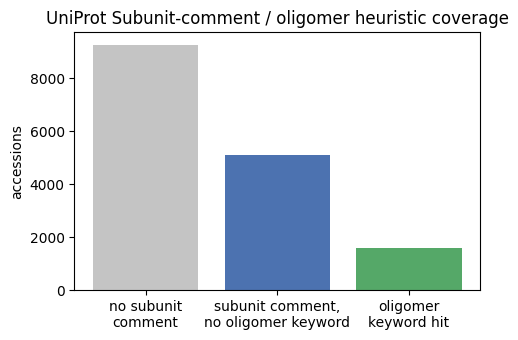

In [10]:
OLIGOMER_KEYWORDS = [
    "homodimer", "homotrimer", "homotetramer", "homopentamer", "homohexamer",
    "homooligomer", "homo-oligomer", "oligomerizes", "oligomerization", "dimerizes", "dimerization",
]


def has_oligomer_keyword(subunit_text):
    if not subunit_text:
        return False
    text = subunit_text.lower()
    return any(kw in text for kw in OLIGOMER_KEYWORDS)


for info in uniprot_cache.values():
    info["oligomer_heuristic"] = has_oligomer_keyword(info.get("subunit_text"))

n_with_subunit = sum(1 for info in uniprot_cache.values() if info.get("subunit_text"))
n_oligomer = sum(1 for info in uniprot_cache.values() if info["oligomer_heuristic"])
print(f"{n_with_subunit}/{len(uniprot_cache)} accessions have a Subunit-structure comment")
print(f"{n_oligomer}/{len(uniprot_cache)} flagged as likely self-oligomeric by keyword heuristic")

save_uniprot_cache(uniprot_cache, UNIPROT_CACHE_PATH)

fig, ax = plt.subplots(figsize=(5, 3.5))
labels = ["no subunit\ncomment", "subunit comment,\nno oligomer keyword", "oligomer\nkeyword hit"]
counts = [
    len(uniprot_cache) - n_with_subunit,
    n_with_subunit - n_oligomer,
    n_oligomer,
]
ax.bar(labels, counts, color=["#C4C4C4", "#4C72B0", "#55A868"])
ax.set_ylabel("accessions")
ax.set_title("UniProt Subunit-comment / oligomer heuristic coverage")
plt.tight_layout()
plt.show()

## 4. cd-hit cross-reference

Pool MaSIF `domain_seq` (short, one row per AlphaFold domain — already 1 row per `P1_id` in
`021structure_C_mimicry_postprocessed.csv`, though 67 domain sequences are shared by more than one `P1_id`,
e.g. true paralogs/duplicated TED entries) together with the IP-MS full-length sequences fetched in Section 3,
and run a single `cd-hit -c 0.98` pass, adapting the `cd-hit` subprocess + `.clstr`-parsing pattern already
used in `notebooks/NUP98_mimicry_library.ipynb` (cell 14). Unlike that notebook — which *dedupes* a single
dataframe to one row per cluster — we keep every row and instead use cluster membership as a **join key**
between the two sequence pools: a MaSIF domain and an IP-MS accession that land in the same cluster are the
same protein by sequence, regardless of their (possibly different) UniProt accessions.

`domain_seq` (short) vs. IP-MS `sequence` (full-length) is exactly the "identity over the aligned region of
the shorter sequence" case described in the task: cd-hit's default identity is computed over the alignment,
so a domain fully contained in a longer protein clusters correctly without needing `-aS/-aL` coverage flags.

We report two confidence tiers, kept separate rather than collapsed: `exact_accession_match` (MaSIF
`uniprot_accn` equals the IP-MS accession — same protein, unambiguous) vs. `cluster_match` (same cd-hit
cluster, but not necessarily the same accession — could be a paralog/isoform-level match, still worth
seeing but a notch lower confidence).

In [11]:
import hashlib
import os
import shutil
import subprocess
import sys
import tempfile

CDHIT_IDENTITY = 0.98
CDHIT_WORD_SIZE = 5  # required by cd-hit for -c in [0.7, 1.0]
CDHIT_CACHE_PATH = IPMS_DIR / "cdhit_clusters.json"

# Resolve cd-hit relative to sys.executable rather than trusting inherited PATH: the notebook kernel is
# the MaSIF conda env's python, but a Jupyter server started from a different env won't necessarily put
# that env's bin/ on PATH even though the kernel itself is correct.
CDHIT_BIN = shutil.which("cd-hit") or str(Path(sys.executable).parent / "cd-hit")


def parse_cd_hit_clstr(clstr_path):
    """Return list of clusters; each cluster is a list of FASTA header ids (as written, sans '>'/'...')."""
    clusters = []
    current = []
    with open(clstr_path) as fh:
        for line in fh:
            line = line.rstrip()
            if line.startswith(">Cluster"):
                if current:
                    clusters.append(current)
                current = []
            elif line:
                m = re.search(r">(.+?)\.\.\.", line)
                if not m:
                    raise ValueError(f"Could not parse cd-hit clstr line: {line!r}")
                current.append(m.group(1))
        if current:
            clusters.append(current)
    return clusters


# One row per unique MaSIF domain sequence (postprocessed.csv is already 1 row/P1_id; 67 domain_seq values
# are shared by >1 P1_id -- we cluster each unique sequence once and join back to every mimicry_df row after).
masif_seq_lookup = (
    mimicry_df[["P1_id", "domain_seq"]].drop_duplicates(subset=["domain_seq"]).reset_index(drop=True)
)
ipms_seq_lookup = pd.DataFrame(
    [
        (acc, uniprot_cache[acc]["sequence"])
        for acc in unique_accessions
        if uniprot_cache.get(acc, {}).get("sequence")
    ],
    columns=["accession", "sequence"],
)
print(f"{len(masif_seq_lookup)} unique MaSIF domain sequences (from {len(mimicry_df)} rows)")
print(f"{len(ipms_seq_lookup)} IP-MS accessions with a sequence to pool in")

22404 unique MaSIF domain sequences (from 22471 rows)
15951 IP-MS accessions with a sequence to pool in


In [12]:
# Bounded memory is essential, not just polite: `-M 0` (unlimited) disables cd-hit's memory-bounded
# algorithm, which on this pool made it ~18x slower (7 min vs 23 s) AND let it balloon until the OOM
# killer took it (exit 137) on a busy shared node. A 16 GB cap actually peaks at ~0.4 GB.
CDHIT_MEMORY_MB = 16000
CDHIT_THREADS = int(os.environ.get("SLURM_CPUS_PER_TASK", 8))  # don't grab all cores on a shared node

# Build the exact FASTA we would cluster, then key the cache on its content + the cd-hit parameters.
# Hashing the content (rather than trusting "sequences never change") means the cache self-invalidates
# if the library, the UniProt cache, or CDHIT_IDENTITY/CDHIT_WORD_SIZE ever do change.
fasta_lines = []
for i, seq in enumerate(masif_seq_lookup["domain_seq"]):
    fasta_lines.append(f">masif::{i}\n{seq}\n")
for acc, seq in zip(ipms_seq_lookup["accession"], ipms_seq_lookup["sequence"]):
    fasta_lines.append(f">ipms::{acc}\n{seq}\n")
fasta_text = "".join(fasta_lines)

cdhit_key = hashlib.sha256(
    f"c={CDHIT_IDENTITY};n={CDHIT_WORD_SIZE}\n".encode() + fasta_text.encode()
).hexdigest()

clusters = None
if CDHIT_CACHE_PATH.is_file():
    with open(CDHIT_CACHE_PATH) as fh:
        cached = json.load(fh)
    if cached.get("key") == cdhit_key:
        clusters = cached["clusters"]
        print(f"Loaded cd-hit clustering from cache: {CDHIT_CACHE_PATH.name} (key {cdhit_key[:12]}...)")
    else:
        print("Cache present but inputs/parameters changed -> re-running cd-hit")

if clusters is None:
    if not Path(CDHIT_BIN).is_file():
        raise FileNotFoundError(
            f"cd-hit not found (tried {CDHIT_BIN}) and no valid cache at {CDHIT_CACHE_PATH}; "
            "is the kernel using the MaSIF conda env?"
        )
    with tempfile.TemporaryDirectory(prefix="cdhit_crossref_") as tmpdir:
        tmpdir = Path(tmpdir)
        fasta_in = tmpdir / "pooled.fa"
        fasta_in.write_text(fasta_text)
        fasta_out = tmpdir / "pooled_cdhit"
        cmd = [
            CDHIT_BIN,
            "-i", str(fasta_in),
            "-o", str(fasta_out),
            "-c", str(CDHIT_IDENTITY),
            "-n", str(CDHIT_WORD_SIZE),
            "-d", "0",
            "-M", str(CDHIT_MEMORY_MB),
            "-T", str(CDHIT_THREADS),
        ]
        result = subprocess.run(cmd, capture_output=True, text=True)
        if result.returncode != 0:
            print(result.stdout[-3000:])
            print(result.stderr[-3000:])
            hint = ""
            if result.returncode in (137, -9):
                hint = " -- exit 137 means the OOM killer stopped it; lower CDHIT_THREADS or CDHIT_MEMORY_MB."
            raise RuntimeError(f"cd-hit failed (exit {result.returncode}){hint}")
        clusters = parse_cd_hit_clstr(Path(f"{fasta_out}.clstr"))

    with open(CDHIT_CACHE_PATH, "w") as fh:
        json.dump({"key": cdhit_key, "clusters": clusters}, fh)
    print(f"Ran cd-hit (-T {CDHIT_THREADS}, -M {CDHIT_MEMORY_MB}) and cached to {CDHIT_CACHE_PATH.name}")

n_pooled = len(masif_seq_lookup) + len(ipms_seq_lookup)
n_multi = sum(1 for c in clusters if len(c) > 1)
print(f"cd-hit (-c {CDHIT_IDENTITY}): {n_pooled} sequences -> {len(clusters)} clusters ({n_multi} multi-member)")

Loaded cd-hit clustering from cache: cdhit_clusters.json (key 06d1ed4985b9...)
cd-hit (-c 0.98): 38355 sequences -> 26177 clusters (4850 multi-member)


In [13]:
masif_to_ipms = {i: set() for i in range(len(masif_seq_lookup))}
for cluster in clusters:
    masif_members = [m for m in cluster if m.startswith("masif::")]
    ipms_members = [m for m in cluster if m.startswith("ipms::")]
    if masif_members and ipms_members:
        ipms_accs = {m.split("::", 1)[1] for m in ipms_members}
        for m in masif_members:
            idx = int(m.split("::", 1)[1])
            masif_to_ipms[idx].update(ipms_accs)

masif_seq_lookup["ipms_cluster_matches"] = [sorted(masif_to_ipms[i]) for i in range(len(masif_seq_lookup))]
masif_seq_lookup["n_ipms_cluster_matches"] = masif_seq_lookup["ipms_cluster_matches"].str.len()

n_matched = (masif_seq_lookup["n_ipms_cluster_matches"] > 0).sum()
print(f"{n_matched}/{len(masif_seq_lookup)} unique MaSIF domains share a cd-hit cluster with >=1 IP-MS accession")

mimicry_df = mimicry_df.merge(
    masif_seq_lookup[["domain_seq", "ipms_cluster_matches", "n_ipms_cluster_matches"]],
    on="domain_seq",
    how="left",
)
mimicry_df["cluster_match"] = mimicry_df["n_ipms_cluster_matches"] > 0
mimicry_df["exact_accession_match"] = [
    accn in matches for accn, matches in zip(mimicry_df["uniprot_accn"], mimicry_df["ipms_cluster_matches"])
]

n_rows_matched = mimicry_df["cluster_match"].sum()
n_rows_exact = mimicry_df["exact_accession_match"].sum()
print(
    f"Across all {len(mimicry_df)} mimicry rows: {n_rows_matched} cluster_match, "
    f"{n_rows_exact} exact_accession_match (subset of cluster_match)"
)
assert n_rows_exact <= n_rows_matched

6910/22404 unique MaSIF domains share a cd-hit cluster with >=1 IP-MS accession
Across all 22471 mimicry rows: 6939 cluster_match, 6157 exact_accession_match (subset of cluster_match)


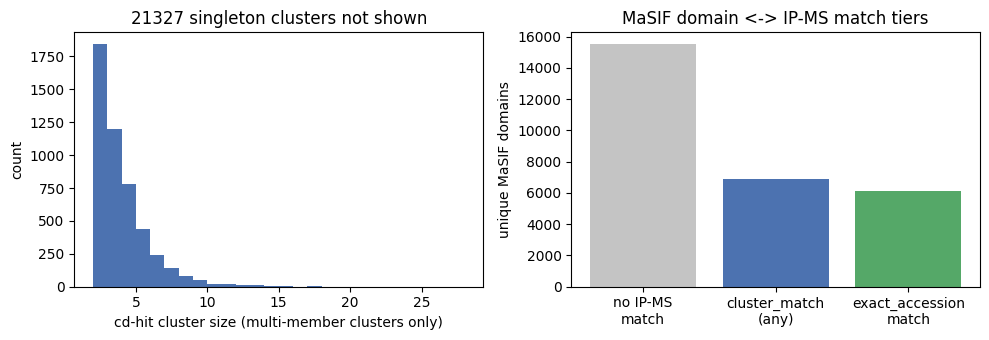

In [14]:
cluster_sizes = [len(c) for c in clusters]

# exact_accession_match at unique-domain granularity (mimicry_df has it at full-row granularity already)
masif_seq_lookup["exact_accession_match"] = (
    mimicry_df.drop_duplicates("domain_seq")
    .set_index("domain_seq")
    .loc[masif_seq_lookup["domain_seq"], "exact_accession_match"]
    .values
)
n_exact_unique = masif_seq_lookup["exact_accession_match"].sum()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

axes[0].hist([s for s in cluster_sizes if s > 1], bins=range(2, max(cluster_sizes) + 2), color="#4C72B0")
axes[0].set_xlabel("cd-hit cluster size (multi-member clusters only)")
axes[0].set_ylabel("count")
axes[0].set_title(f"{sum(1 for s in cluster_sizes if s == 1)} singleton clusters not shown")

axes[1].bar(
    ["no IP-MS\nmatch", "cluster_match\n(any)", "exact_accession\nmatch"],
    [len(masif_seq_lookup) - n_matched, n_matched, n_exact_unique],
    color=["#C4C4C4", "#4C72B0", "#55A868"],
)
axes[1].set_ylabel("unique MaSIF domains")
axes[1].set_title("MaSIF domain <-> IP-MS match tiers")

plt.tight_layout()
plt.show()

## 5. Score & combine evidence criteria (dynamic thresholds)

**Fragment data is excluded from here on.** The recombinant-fragment-vs-lysate pulldown is dominated by
abundant sticky proteins, and the two assays are not interchangeable — only `TRIM21-FL` (in-cell) is used
for the criteria below. PLRX and BMS are treated as **two independent criteria**, not OR'd together.

### Why not p < 0.05?

The known substrate NUP98 — the protein this whole mimicry campaign is built on — **fails a p<0.05 gate for
PLRX** (p = 0.23), despite having the 16th-largest logFC of 3745 proteins (+3.63). With n=3 replicates the
p-value is noise-dominated while the effect size is unambiguous. Benjamini-Hochberg is worse still: q<0.05
retains 1 protein for PLRX and 0 for BMS. A p-value-first definition throws away ground truth.

### IP-MS axis: robust empirical null (median + k·MAD), calibrated on NUP98

We estimate the null from the bulk of the logFC distribution itself, **per compound**, and call enrichment
as a tail excursion beyond `median + k·MAD` (MAD scaled by 1.4826 to be a robust σ). Per-compound matters:
PLRX carries a global **+0.54** offset while BMS is centred at 0.00, so one shared absolute logFC cutoff
would mean different things for each. NUP98 sits ~7 MADs out in *both* compounds, so `IPMS_MAD_K` can be
tuned for shortlist size while ground truth is retained (k=4 → ~54 PLRX / ~51 BMS). p-values are recorded in
the output but do not gate.

### MaSIF axis: explicit percentile

There is **no correlation between MaSIF-score and IP-MS enrichment** on this data (Spearman ρ = −0.01,
p = 0.59 for PLRX across 3062 shared proteins), so there is no cross-dataset signal against which to
calibrate an "optimal" structural cutoff — elbow-finding here would be fitting noise. Rather than imply a
calibrated threshold, `high_masif_score` is stated plainly as **the top N% of search hits by MaSIF-score**.
For reference, the legacy fixed `MaSIF-score ≥ 0.5` is the top **27.4%** of hits on its own, and the old
`MaSIF-score ≥ 0.5 AND cluster_size ≥ 40` conjunction was about the top 12%. This replaces that conjunction
with a percentile on score alone; `cluster_size` is retained as a reported column and is an axis of the
Section 7 plot.

Four independent criteria: `fl_prlx_enriched`, `fl_bms_enriched`, `high_masif_score`, `oligomer_heuristic`.
Because the axes are uncorrelated, `n_criteria_met` is a triage aid for a hypothesis-generating list — not a
statistically calibrated joint score.

In [15]:
# --- Stringency knobs -------------------------------------------------------
IPMS_MAD_K = 4.0          # enrichment threshold = median + k * MAD-sigma of the FL logFC null
MASIF_TOP_PERCENT = 10.0  # high_masif_score = top N% of search hits by MaSIF-score
# ----------------------------------------------------------------------------

IPMS_DATASET = "FL"  # fragment data deliberately excluded (see markdown above)
COMPOUNDS = ["prlx", "bms"]
POSITIVE_CONTROL_GENE = "NUP98"

fl_results = ipms_results[IPMS_DATASET]


def robust_null(values):
    """Median and MAD-derived sigma of the bulk (non-responder) part of a logFC distribution."""
    x = pd.Series(values).dropna()
    med = float(np.median(x))
    mad_sigma = float(np.median(np.abs(x - med)) * 1.4826)
    return med, mad_sigma


compound_null = {}
for compound in COMPOUNDS:
    med, mad_sigma = robust_null(fl_results[f"logFC_{compound}"])
    compound_null[compound] = {
        "median": med,
        "mad_sigma": mad_sigma,
        "threshold": med + IPMS_MAD_K * mad_sigma,
    }

print(f"Robust empirical null from {IPMS_DATASET} logFC (k={IPMS_MAD_K}):")
for compound, null in compound_null.items():
    print(
        f"  {compound.upper():4s} median={null['median']:+.3f}  MAD-sigma={null['mad_sigma']:.3f}"
        f"  ->  enriched if logFC > {null['threshold']:+.3f}"
    )

# Positive-control calibration: NUP98 is a known TRIM21-PLRX/BMS substrate and MUST survive the threshold.
pc = fl_results[fl_results["Gene names"].astype(str).str.contains(POSITIVE_CONTROL_GENE, na=False)]
print(f"\nPositive-control calibration ({POSITIVE_CONTROL_GENE}):")
if pc.empty:
    print(f"  WARNING: {POSITIVE_CONTROL_GENE} not found in {IPMS_DATASET} results - cannot calibrate.")
else:
    pc_row = pc.iloc[0]
    for compound, null in compound_null.items():
        value = pc_row[f"logFC_{compound}"]
        z = (value - null["median"]) / null["mad_sigma"]
        verdict = "PASS" if value > null["threshold"] else "*** LOST - lower IPMS_MAD_K ***"
        print(
            f"  {compound.upper():4s} logFC={value:+.2f} ({z:.1f} MADs, p={pc_row[f'pval_{compound}']:.3f})"
            f"  ->  {verdict}"
        )

Robust empirical null from FL logFC (k=4.0):
  PRLX median=+0.538  MAD-sigma=0.441  ->  enriched if logFC > +2.300
  BMS  median=+0.000  MAD-sigma=0.324  ->  enriched if logFC > +1.298

Positive-control calibration (NUP98):
  PRLX logFC=+3.63 (7.0 MADs, p=0.230)  ->  PASS
  BMS  logFC=+2.33 (7.2 MADs, p=0.032)  ->  PASS


In [16]:
fl_gmap = gene_accession_maps[IPMS_DATASET]

records = []
for idx in fl_results.index:
    row = fl_results.loc[idx]
    shared = {"gene_names": row["Gene names"]}
    for compound in COMPOUNDS:
        logfc = row[f"logFC_{compound}"]
        shared[f"logFC_{compound}"] = logfc
        shared[f"pval_{compound}"] = row[f"pval_{compound}"]
        # Enrichment only: a *depleted* protein (logFC < 0) is never a candidate glue substrate.
        shared[f"enriched_{compound}"] = bool(
            pd.notna(logfc) and logfc > compound_null[compound]["threshold"]
        )
    for accession in fl_gmap.loc[idx, "accessions"]:
        records.append({"accession": canonical_accession(accession), **shared})

fl_long = pd.DataFrame(records)

agg_spec = {"gene_names": lambda s: ";".join(sorted(set(s)))}
for compound in COMPOUNDS:
    agg_spec[f"logFC_{compound}"] = "max"   # best evidence across accessions sharing this protein group
    agg_spec[f"pval_{compound}"] = "min"
    agg_spec[f"enriched_{compound}"] = "any"

fl_by_accession = fl_long.groupby("accession").agg(agg_spec)
fl_accession_lookup = fl_by_accession.to_dict("index")

print(f"{len(fl_by_accession)} unique accessions carry {IPMS_DATASET} IP-MS evidence")
for compound in COMPOUNDS:
    n = fl_by_accession[f"enriched_{compound}"].sum()
    print(f"  {compound.upper():4s} enriched: {n} accessions")
print(
    f"  both compounds:   {(fl_by_accession['enriched_prlx'] & fl_by_accession['enriched_bms']).sum()} accessions"
)

12533 unique accessions carry FL IP-MS evidence
  PRLX enriched: 183 accessions
  BMS  enriched: 211 accessions
  both compounds:   24 accessions


In [17]:
def passes_filter_set(df, filters):
    mask = pd.Series(True, index=df.index)
    for col, bounds in filters.items():
        if bounds.get("min") is not None:
            mask &= df[col] >= bounds["min"]
        if bounds.get("max") is not None:
            mask &= df[col] <= bounds["max"]
    return mask


# Percentile-based structural threshold, stated as a rank rather than an implied-calibrated score.
masif_score_cutoff = float(mimicry_df["MaSIF-score"].quantile(1 - MASIF_TOP_PERCENT / 100))
mimicry_df["high_masif_score"] = mimicry_df["MaSIF-score"] >= masif_score_cutoff

# Bonus flag (unchanged): the full structural/biological filter set from the domain-library JSON.
mimicry_df["passes_full_filters"] = passes_filter_set(mimicry_df, mimicry_filters)

legacy_cutoff = mimicry_filters["MaSIF-score"]["min"]
legacy_percentile = 100 * (mimicry_df["MaSIF-score"] >= legacy_cutoff).mean()
print(
    f"high_masif_score = top {MASIF_TOP_PERCENT}% of MaSIF-score  ->  cutoff {masif_score_cutoff:.4f}, "
    f"{mimicry_df['high_masif_score'].sum()} / {len(mimicry_df)} rows"
)
print(
    f"  (for reference, the legacy fixed cutoff {legacy_cutoff} corresponds to the top "
    f"{legacy_percentile:.1f}% of hits)"
)
print(f"passes_full_filters (bonus): {mimicry_df['passes_full_filters'].sum()} / {len(mimicry_df)} rows")

high_masif_score = top 10.0% of MaSIF-score  ->  cutoff 0.5239, 2248 / 22471 rows
  (for reference, the legacy fixed cutoff 0.5 corresponds to the top 27.4% of hits)
passes_full_filters (bonus): 1354 / 22471 rows


In [18]:
FL_ROW_COLUMNS = (
    ["fl_gene_names"]
    + [f"fl_logFC_{c}" for c in COMPOUNDS]
    + [f"fl_pval_{c}" for c in COMPOUNDS]
    + [f"fl_{c}_enriched" for c in COMPOUNDS]
)


def summarize_row_fl(accessions):
    """Aggregate FL IP-MS evidence across every cd-hit cluster-mate accession of one MaSIF domain."""
    infos = [fl_accession_lookup[a] for a in accessions if a in fl_accession_lookup]
    if not infos:
        return pd.Series(
            [None] + [np.nan] * (2 * len(COMPOUNDS)) + [False] * len(COMPOUNDS),
            index=FL_ROW_COLUMNS,
        )
    values = {"fl_gene_names": ";".join(sorted({g for i in infos for g in i["gene_names"].split(";")}))}
    for compound in COMPOUNDS:
        logfcs = [i[f"logFC_{compound}"] for i in infos if pd.notna(i[f"logFC_{compound}"])]
        pvals = [i[f"pval_{compound}"] for i in infos if pd.notna(i[f"pval_{compound}"])]
        values[f"fl_logFC_{compound}"] = max(logfcs) if logfcs else np.nan
        values[f"fl_pval_{compound}"] = min(pvals) if pvals else np.nan
        values[f"fl_{compound}_enriched"] = any(i[f"enriched_{compound}"] for i in infos)
    return pd.Series(values, index=FL_ROW_COLUMNS)


def summarize_row_oligomer(accessions):
    """Oligomer heuristic from cached UniProt Subunit comments of matched accessions; None = unknown."""
    infos = [uniprot_cache[a] for a in accessions if a in uniprot_cache]
    subunit_texts = [i["subunit_text"] for i in infos if i.get("subunit_text")]
    if not subunit_texts:
        return None, None
    return any(i["oligomer_heuristic"] for i in infos), " | ".join(subunit_texts)


mimicry_df[FL_ROW_COLUMNS] = mimicry_df["ipms_cluster_matches"].apply(summarize_row_fl)
mimicry_df["fl_detected"] = mimicry_df["fl_gene_names"].notna()

oligomer_rows = [summarize_row_oligomer(a) for a in mimicry_df["ipms_cluster_matches"]]
mimicry_df["oligomer_heuristic"], mimicry_df["subunit_text"] = zip(*oligomer_rows)

print(f"MaSIF domains with FL IP-MS data: {mimicry_df['fl_detected'].sum()} / {len(mimicry_df)} rows")
for compound in COMPOUNDS:
    print(f"  fl_{compound}_enriched: {mimicry_df[f'fl_{compound}_enriched'].sum()} rows")
print(
    f"oligomer_heuristic: {(mimicry_df['oligomer_heuristic'] == True).sum()} True, "
    f"{(mimicry_df['oligomer_heuristic'] == False).sum()} False, "
    f"{mimicry_df['oligomer_heuristic'].isna().sum()} unknown"
)

MaSIF domains with FL IP-MS data: 5879 / 22471 rows
  fl_prlx_enriched: 55 rows
  fl_bms_enriched: 71 rows
oligomer_heuristic: 1322 True, 4403 False, 16746 unknown


In [19]:
CRITERIA = ["fl_prlx_enriched", "fl_bms_enriched", "high_masif_score", "oligomer_heuristic"]

mimicry_df["n_criteria_met"] = sum(
    (mimicry_df[c] == True).astype(int) for c in CRITERIA  # noqa: E712 (None must not count as True)
)

# Candidate table: MaSIF domains detected in the FL IP-MS experiment at all. Domains never seen in FL
# cannot be evaluated against this hypothesis, whatever their structural score.
candidate_cols = [
    "P1_id", "uniprot_accn", "gene_name", "MaSIF-score", "cluster_size", "cluster_mean_rmsd",
    "exact_accession_match", "ipms_cluster_matches", "fl_gene_names",
    "fl_logFC_prlx", "fl_pval_prlx", "fl_prlx_enriched",
    "fl_logFC_bms", "fl_pval_bms", "fl_bms_enriched",
    "high_masif_score", "passes_full_filters",
    "oligomer_heuristic", "subunit_text",
    "n_criteria_met",
]
candidate_df = (
    mimicry_df.loc[mimicry_df["fl_detected"], candidate_cols]
    .sort_values(["n_criteria_met", "MaSIF-score"], ascending=[False, False])
    .reset_index(drop=True)
)

print(f"candidate_df: {len(candidate_df)} MaSIF domains detected in {IPMS_DATASET} IP-MS")
print(candidate_df["n_criteria_met"].value_counts().sort_index(ascending=False).to_string())
print("\nPer-criterion counts within candidate_df:")
for c in CRITERIA:
    print(f"  {c:20s} {(candidate_df[c] == True).sum()}")  # noqa: E712
candidate_df.head(10)

candidate_df: 5879 MaSIF domains detected in FL IP-MS
n_criteria_met
3       4
2     151
1    1576
0    4148

Per-criterion counts within candidate_df:
  fl_prlx_enriched     55
  fl_bms_enriched      71
  high_masif_score     643
  oligomer_heuristic   1121


,P1_id,uniprot_accn,gene_name,MaSIF-score,cluster_size,cluster_mean_rmsd,exact_accession_match,ipms_cluster_matches,fl_gene_names,fl_logFC_prlx,fl_pval_prlx,fl_prlx_enriched,fl_logFC_bms,fl_pval_bms,fl_bms_enriched,high_masif_score,passes_full_filters,oligomer_heuristic,subunit_text,n_criteria_met
0,P52948-F1-TED01_A,P52948,NUP98,0.825931,171.0,0.800598,True,"[A0A3B3ITD8, A0A8V8TPX4, A0A8V8TRC7, H0YDA1, P...",NUP98,3.634386,0.229975,True,2.332079,0.031991,True,True,True,False,Part of the nuclear pore complex (NPC) (PubMed...,3
1,P23919-F1-TED01_A,P23919,DTYMK,0.531660,87.0,3.372953,True,[P23919],DTYMK,3.400529,0.348249,True,0.000000,0.373901,False,True,True,True,Homodimer,3
2,P39687-F1-TED01_A,P39687,ANP32A,0.526255,26.0,3.220054,True,"[H0YN26, P39687]",ANP32A,2.447526,0.411848,True,1.667970,0.216967,True,True,False,False,"Component of the SET complex, composed of at l...",3
3,O14744-F1-TED01_A,O14744,PRMT5,0.524708,26.0,3.846326,True,[O14744],PRMT5,-0.018071,0.993357,False,1.310239,0.609438,True,True,False,True,"Forms, at least, homodimers and homotetramers ...",3
4,P07814-F1-TED08_A,P07814,EPRS1,0.609597,32.0,1.475192,True,"[P07814, V9GYZ6]",EPRS,0.397663,0.339560,False,0.124843,0.831942,False,True,False,True,"Homodimer (PubMed:23263184, PubMed:24100331, P...",2
5,P53992-F1-TED05_A,P53992,SEC24C,0.596418,57.0,1.305564,True,"[G5EA31, P53992]",SEC24C,1.801425,0.122594,False,1.477911,0.378125,True,True,True,False,COPII is composed of at least five proteins: t...,2
6,Q17RS7-F1-TED02_A,Q17RS7,GEN1,0.593253,49.0,1.644840,True,[Q17RS7],GEN1,0.503703,0.821526,False,0.000000,0.373901,False,True,True,True,"Largely monomeric, dimerizes on the Holliday j...",2
7,Q9Y2I1-F1-TED04_A,Q9Y2I1,NISCH,0.592734,39.0,1.784630,True,[Q9Y2I1],NISCH,0.338738,0.393832,False,0.004378,0.988660,False,True,False,True,Homooligomer. Interacts with GRB2. Interacts w...,2
8,Q96KQ7-F1-TED03_A,Q96KQ7,EHMT2,0.590781,52.0,1.729296,True,"[A0A0G2JK64, A0A0G2JRN8, A2ABF9, Q96KQ7]",EHMT2,0.568373,0.645060,False,-0.713857,0.653091,False,True,True,True,Heterodimer; heterodimerizes with EHMT1/GLP (P...,2
9,O43776-F1-TED03_A,O43776,NARS1,0.585218,116.0,3.871570,True,[O43776],NARS,-0.169970,0.777567,False,0.194773,0.778909,False,True,True,True,Homodimer,2


## 6. Visualization + ranked candidate export

Volcano plots are now **FL only**, one panel per compound, with the `median + k·MAD` enrichment threshold
drawn as a vertical line and NUP98 annotated so you can see where ground truth falls relative to the cut.
Note how NUP98 sits far to the right but *low* on the PLRX y-axis — that is the p-value problem, visually.

The MaSIF-score vs. cluster_size scatter shows the structural axis with the percentile cutoff marked, and
the criteria bar shows how the 4 independent criteria stack up.

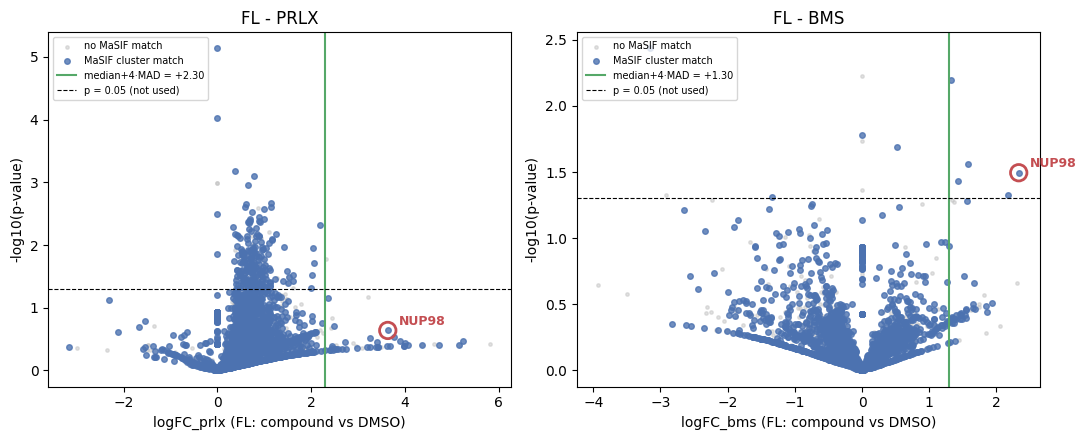

In [20]:
matched_ipms_accessions = set()
for accs in mimicry_df.loc[mimicry_df["cluster_match"], "ipms_cluster_matches"]:
    matched_ipms_accessions.update(accs)

accs_per_row = fl_gmap.loc[fl_results.index, "accessions"]
has_masif_match = accs_per_row.apply(
    lambda accs: any(canonical_accession(a) in matched_ipms_accessions for a in accs)
).values

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, compound in zip(axes, COMPOUNDS):
    x = fl_results[f"logFC_{compound}"]
    y = -np.log10(fl_results[f"pval_{compound}"])
    ax.scatter(x[~has_masif_match], y[~has_masif_match], s=6, color="#C4C4C4", alpha=0.5, label="no MaSIF match")
    ax.scatter(x[has_masif_match], y[has_masif_match], s=16, color="#4C72B0", alpha=0.8, label="MaSIF cluster match")

    thr = compound_null[compound]["threshold"]
    ax.axvline(thr, color="#55A868", linestyle="-", linewidth=1.5, label=f"median+{IPMS_MAD_K:g}·MAD = {thr:+.2f}")
    ax.axhline(-np.log10(0.05), color="black", linestyle="--", linewidth=0.8, label="p = 0.05 (not used)")

    if not pc.empty:
        px_, py_ = pc_row[f"logFC_{compound}"], -np.log10(pc_row[f"pval_{compound}"])
        ax.scatter([px_], [py_], s=140, facecolors="none", edgecolors="#C44E52", linewidths=2, zorder=5)
        ax.annotate(
            POSITIVE_CONTROL_GENE, (px_, py_), textcoords="offset points", xytext=(8, 4),
            color="#C44E52", fontweight="bold", fontsize=9,
        )
    ax.set_xlabel(f"logFC_{compound} ({IPMS_DATASET}: compound vs DMSO)")
    ax.set_ylabel("-log10(p-value)")
    ax.set_title(f"{IPMS_DATASET} - {compound.upper()}")
    ax.legend(fontsize=7, loc="upper left")

plt.tight_layout()
plt.show()

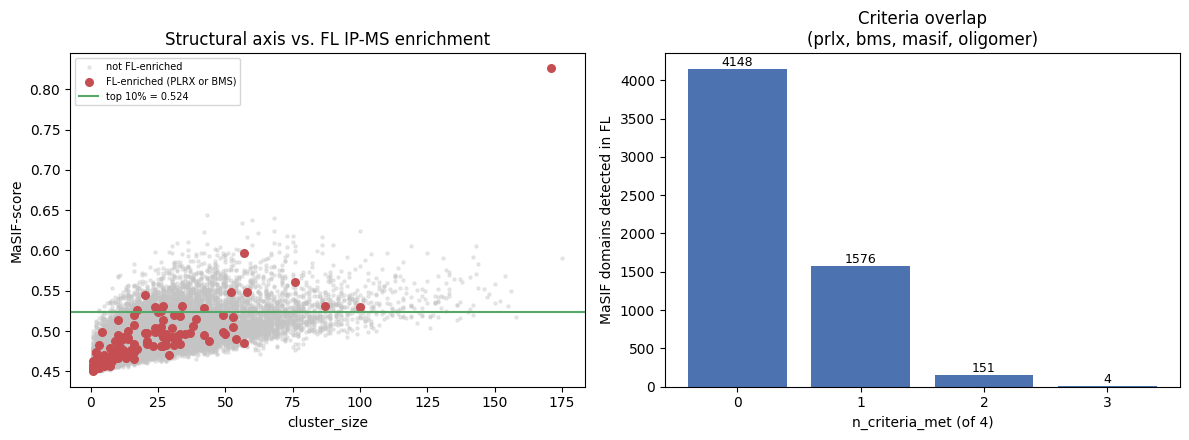

Per-criterion counts (FL-detected domains):
  fl_prlx_enriched        55
  fl_bms_enriched         71
  high_masif_score       643
  oligomer_heuristic    1121


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# --- structural axis, highlighting FL-enriched domains ---
ax = axes[0]
enriched_any = mimicry_df["fl_prlx_enriched"] | mimicry_df["fl_bms_enriched"]
base = mimicry_df[~enriched_any]
hit = mimicry_df[enriched_any]
ax.scatter(base["cluster_size"], base["MaSIF-score"], s=5, color="#C4C4C4", alpha=0.35, label="not FL-enriched")
ax.scatter(hit["cluster_size"], hit["MaSIF-score"], s=30, color="#C44E52", label="FL-enriched (PLRX or BMS)")
ax.axhline(masif_score_cutoff, color="#55A868", linestyle="-", linewidth=1.5,
           label=f"top {MASIF_TOP_PERCENT:g}% = {masif_score_cutoff:.3f}")
ax.set_xlabel("cluster_size")
ax.set_ylabel("MaSIF-score")
ax.set_title("Structural axis vs. FL IP-MS enrichment")
ax.legend(fontsize=7)

# --- criteria stack ---
ax = axes[1]
counts = candidate_df["n_criteria_met"].value_counts().sort_index()
ax.bar(counts.index.astype(str), counts.values, color="#4C72B0")
for i, v in zip(counts.index, counts.values):
    ax.text(str(i), v, str(v), ha="center", va="bottom", fontsize=9)
ax.set_xlabel("n_criteria_met (of 4)")
ax.set_ylabel("MaSIF domains detected in FL")
ax.set_title("Criteria overlap\n(prlx, bms, masif, oligomer)")

plt.tight_layout()
plt.show()

print("Per-criterion counts (FL-detected domains):")
for c in CRITERIA:
    print(f"  {c:20s} {(candidate_df[c] == True).sum():5d}")  # noqa: E712

In [22]:
CANDIDATE_CSV_PATH = IPMS_DIR / "trim21_masif_crossref_candidates.csv"
candidate_df.to_csv(CANDIDATE_CSV_PATH, index=False)
print(f"Wrote {len(candidate_df)} rows to {CANDIDATE_CSV_PATH}")

top = candidate_df[candidate_df["n_criteria_met"] >= 3]
print(f"\nCandidates meeting >=3 of 4 criteria: {len(top)}")
top

Wrote 5879 rows to /scratch/ymeng/masif_seed_mimicry/masif_mimicry/data/TRIM21_IP-MS/trim21_masif_crossref_candidates.csv

Candidates meeting >=3 of 4 criteria: 4


,P1_id,uniprot_accn,gene_name,MaSIF-score,cluster_size,cluster_mean_rmsd,exact_accession_match,ipms_cluster_matches,fl_gene_names,fl_logFC_prlx,fl_pval_prlx,fl_prlx_enriched,fl_logFC_bms,fl_pval_bms,fl_bms_enriched,high_masif_score,passes_full_filters,oligomer_heuristic,subunit_text,n_criteria_met
0,P52948-F1-TED01_A,P52948,NUP98,0.825931,171.0,0.800598,True,"[A0A3B3ITD8, A0A8V8TPX4, A0A8V8TRC7, H0YDA1, P...",NUP98,3.634386,0.229975,True,2.332079,0.031991,True,True,True,False,Part of the nuclear pore complex (NPC) (PubMed...,3
1,P23919-F1-TED01_A,P23919,DTYMK,0.531660,87.0,3.372953,True,[P23919],DTYMK,3.400529,0.348249,True,0.000000,0.373901,False,True,True,True,Homodimer,3
2,P39687-F1-TED01_A,P39687,ANP32A,0.526255,26.0,3.220054,True,"[H0YN26, P39687]",ANP32A,2.447526,0.411848,True,1.667970,0.216967,True,True,False,False,"Component of the SET complex, composed of at l...",3
3,O14744-F1-TED01_A,O14744,PRMT5,0.524708,26.0,3.846326,True,[O14744],PRMT5,-0.018071,0.993357,False,1.310239,0.609438,True,True,False,True,"Forms, at least, homodimers and homotetramers ...",3


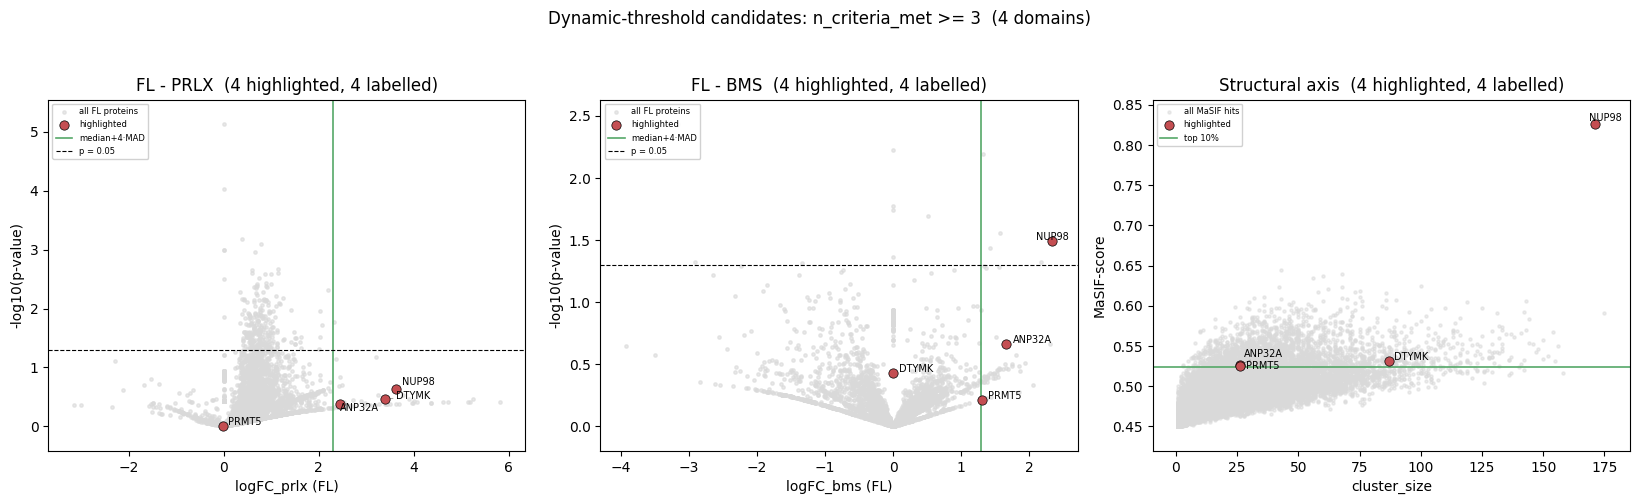

Highlighted domains:
gene_name uniprot_accn  MaSIF-score  cluster_size  fl_logFC_prlx  fl_logFC_bms oligomer_heuristic  n_criteria_met
   ANP32A       P39687     0.526255          26.0       2.447526      1.667970              False               3
    NUP98       P52948     0.825931         171.0       3.634386      2.332079              False               3
    PRMT5       O14744     0.524708          26.0      -0.018071      1.310239               True               3
    DTYMK       P23919     0.531660          87.0       3.400529      0.000000               True               3


In [23]:
from adjustText import adjust_text

# Accession -> FL result row indices, so a highlighted MaSIF domain can be located on the volcanoes
# (the volcano is one point per IP-MS protein group; the highlight sets are per MaSIF domain).
acc_to_fl_rows = {}
for idx in fl_results.index:
    for a in fl_gmap.loc[idx, "accessions"]:
        acc_to_fl_rows.setdefault(canonical_accession(a), set()).add(idx)


def fl_rows_for_domains(domain_index):
    rows = set()
    if len(domain_index) == 0:
        return []
    for accs in mimicry_df.loc[list(domain_index), "ipms_cluster_matches"]:
        for a in accs:
            rows |= acc_to_fl_rows.get(a, set())
    return sorted(rows)


def domain_label(row):
    """Best available gene symbol for a MaSIF domain row."""
    for key in ("gene_name", "fl_gene_names", "uniprot_accn"):
        value = row.get(key)
        if pd.notna(value) and str(value).strip():
            return str(value).split(";")[0]
    return "?"


def plot_candidate_panels(volcano_domains, scatter_domains, title, max_labels=15,
                          color="#C44E52", logfc_lines=None, masif_line=None):
    """Two FL volcanoes + the MaSIF-score/cluster_size scatter, with one highlight set labelled by gene.

    volcano_domains: {compound: mimicry_df index labels to highlight in that compound's panel}
    scatter_domains: mimicry_df index labels to highlight in the structural panel
    logfc_lines: {compound: (x, label)} vertical line per volcano; defaults to the Section 5 MAD thresholds
    masif_line: (y, label) horizontal line on the structural panel; defaults to the percentile cutoff
    """
    if logfc_lines is None:
        logfc_lines = {
            c: (compound_null[c]["threshold"], f"median+{IPMS_MAD_K:g}·MAD") for c in COMPOUNDS
        }
    if masif_line is None:
        masif_line = (masif_score_cutoff, f"top {MASIF_TOP_PERCENT:g}%")
    fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))

    for ax, compound in zip(axes[:2], COMPOUNDS):
        x = fl_results[f"logFC_{compound}"]
        y = -np.log10(fl_results[f"pval_{compound}"])
        ax.scatter(x, y, s=6, color="#D9D9D9", alpha=0.6, zorder=1, label="all FL proteins")

        rows = fl_rows_for_domains(volcano_domains[compound])
        if rows:
            ax.scatter(x.loc[rows], y.loc[rows], s=45, color=color, edgecolors="black",
                       linewidths=0.5, zorder=3, label="highlighted")
            ranked = sorted(rows, key=lambda r: x.loc[r] if pd.notna(x.loc[r]) else -np.inf, reverse=True)
            texts = [
                ax.text(x.loc[r], y.loc[r], str(fl_results.loc[r, "Gene names"]).split(";")[0],
                        fontsize=7, zorder=4)
                for r in ranked[:max_labels] if pd.notna(x.loc[r]) and pd.notna(y.loc[r])
            ]
            if texts:
                adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="gray", lw=0.5))

        vline_x, vline_label = logfc_lines[compound]
        ax.axvline(vline_x, color="#55A868", lw=1.2, label=vline_label)
        ax.axhline(-np.log10(0.05), color="black", ls="--", lw=0.8, label="p = 0.05")
        ax.set_xlabel(f"logFC_{compound} ({IPMS_DATASET})")
        ax.set_ylabel("-log10(p-value)")
        n_lab = min(len(rows), max_labels)
        ax.set_title(f"{IPMS_DATASET} - {compound.upper()}  ({len(rows)} highlighted, {n_lab} labelled)")
        ax.margins(x=0.06, y=0.08)
        ax.legend(fontsize=6, loc="upper left", framealpha=0.9)

    ax = axes[2]
    ax.scatter(mimicry_df["cluster_size"], mimicry_df["MaSIF-score"], s=5, color="#D9D9D9",
               alpha=0.5, zorder=1, label="all MaSIF hits")
    sel = mimicry_df.loc[list(scatter_domains)] if len(scatter_domains) else mimicry_df.iloc[0:0]
    if len(sel):
        ax.scatter(sel["cluster_size"], sel["MaSIF-score"], s=45, color=color, edgecolors="black",
                   linewidths=0.5, zorder=3, label="highlighted")
        texts = [
            ax.text(r["cluster_size"], r["MaSIF-score"], domain_label(r), fontsize=7, zorder=4)
            for _, r in sel.sort_values("MaSIF-score", ascending=False).head(max_labels).iterrows()
        ]
        if texts:
            adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="gray", lw=0.5))
    hline_y, hline_label = masif_line
    ax.axhline(hline_y, color="#55A868", lw=1.2, label=hline_label)
    ax.set_xlabel("cluster_size")
    ax.set_ylabel("MaSIF-score")
    ax.set_title(f"Structural axis  ({len(sel)} highlighted, {min(len(sel), max_labels)} labelled)")
    ax.margins(x=0.06, y=0.08)
    ax.legend(fontsize=6, loc="upper left", framealpha=0.9)

    fig.suptitle(title, fontsize=12, y=1.04)
    plt.tight_layout()
    plt.show()


# --- Section 6 highlight set: domains meeting >=3 of the 4 criteria ---
top_domains = mimicry_df.index[mimicry_df["n_criteria_met"] >= 3]
plot_candidate_panels(
    volcano_domains={c: top_domains for c in COMPOUNDS},
    scatter_domains=top_domains,
    title=f"Dynamic-threshold candidates: n_criteria_met >= 3  ({len(top_domains)} domains)",
)
print("Highlighted domains:")
print(
    mimicry_df.loc[top_domains, ["gene_name", "uniprot_accn", "MaSIF-score", "cluster_size",
                                 "fl_logFC_prlx", "fl_logFC_bms", "oligomer_heuristic", "n_criteria_met"]]
    .to_string(index=False)
)

## 7. Manual inspection: fixed cutoffs + interactive plot

An alternative, deliberately simple selection for eyeballing — independent of Section 5/6's dynamic
thresholds, so the two can be compared:

- **IP-MS**: in FL, a domain must be **both `p < 0.05` and `logFC >= 1`**, evaluated **per compound** (it
  enters the PLRX panel if `fl_pval_prlx < 0.05 and fl_logFC_prlx >= 1`, and the BMS panel on the
  equivalent BMS condition). Requiring a positive logFC floor also removes the depleted proteins that a
  p-value-only gate lets through.
- **MaSIF**: `MaSIF-score > 0.5` (the original fixed cutoff).

Plotted as `logFC ~ cluster_size`, one panel per compound, coloured by oligomer evidence, with gene name
and all supporting numbers in the hover tooltip.

Worth remembering while inspecting: NUP98 will **not** appear in the PLRX panel (p = 0.23 fails the
p-value gate even though its logFC of +3.63 is the 16th largest of 3745), which is exactly the tradeoff
Section 5 avoids. A standalone HTML copy is written next to the CSV so the plot is viewable outside the
notebook.

In [24]:
import plotly.express as px
import plotly.io as pio

MANUAL_PVAL_CUTOFF = 0.05
MANUAL_LOGFC_CUTOFF = 1.0
MANUAL_MASIF_CUTOFF = 0.5

OLIGOMER_LABELS = {True: "oligomer evidence", False: "no oligomer keyword", None: "unknown (no UniProt subunit)"}
OLIGOMER_COLORS = {
    "oligomer evidence": "#C44E52",
    "no oligomer keyword": "#4C72B0",
    "unknown (no UniProt subunit)": "#BBBBBB",
}


def manual_selection_mask(compound):
    """p < cutoff AND logFC >= cutoff for this compound, AND MaSIF-score above its cutoff."""
    return (
        (mimicry_df[f"fl_pval_{compound}"] < MANUAL_PVAL_CUTOFF)
        & (mimicry_df[f"fl_logFC_{compound}"] >= MANUAL_LOGFC_CUTOFF)
        & (mimicry_df["MaSIF-score"] > MANUAL_MASIF_CUTOFF)
    )


# Long format: one row per (MaSIF domain, compound) where THAT compound passes both IP-MS cutoffs.
panels = []
for compound in COMPOUNDS:
    sel = mimicry_df[manual_selection_mask(compound)].copy()
    sel["compound"] = compound.upper()
    sel["logFC"] = sel[f"fl_logFC_{compound}"]
    sel["pval"] = sel[f"fl_pval_{compound}"]
    panels.append(sel)

manual_df = pd.concat(panels, ignore_index=True)
manual_df["oligomer"] = manual_df["oligomer_heuristic"].map(
    lambda v: OLIGOMER_LABELS[v if v in (True, False) else None]
)
manual_df["gene"] = manual_df["gene_name"].fillna(manual_df["fl_gene_names"]).fillna(manual_df["uniprot_accn"])
manual_df["subunit_short"] = (
    manual_df["subunit_text"].fillna("(none)").str.slice(0, 160).str.replace(r"\s+", " ", regex=True)
)

print(
    f"Manual-inspection selection (p < {MANUAL_PVAL_CUTOFF}, logFC >= {MANUAL_LOGFC_CUTOFF}, "
    f"MaSIF-score > {MANUAL_MASIF_CUTOFF}):"
)
for compound in COMPOUNDS:
    sub = manual_df[manual_df["compound"] == compound.upper()]
    rng = f"{sub['logFC'].min():+.2f}..{sub['logFC'].max():+.2f}" if len(sub) else "n/a"
    print(f"  {compound.upper():4s}: {len(sub):3d} domains, {sub['gene'].nunique():3d} unique genes, logFC {rng}")
print(manual_df["oligomer"].value_counts().to_string())

Manual-inspection selection (p < 0.05, logFC >= 1.0, MaSIF-score > 0.5):
  PRLX:  17 domains,  12 unique genes, logFC +1.02..+2.00
  BMS :   1 domains,   1 unique genes, logFC +2.33..+2.33
oligomer
no oligomer keyword             16
unknown (no UniProt subunit)     1
oligomer evidence                1


In [25]:
fig = px.scatter(
    manual_df,
    x="cluster_size",
    y="logFC",
    color="oligomer",
    color_discrete_map=OLIGOMER_COLORS,
    facet_col="compound",
    hover_name="gene",
    hover_data={
        "P1_id": True,
        "uniprot_accn": True,
        "MaSIF-score": ":.4f",
        "cluster_size": True,
        "logFC": ":+.3f",
        "pval": ":.4f",
        "passes_full_filters": True,
        "subunit_short": True,
        "oligomer": False,
        "compound": False,
    },
    labels={
        "cluster_size": "MaSIF cluster_size",
        "logFC": "logFC (FL, compound vs DMSO)",
        "oligomer": "Oligomer evidence",
        "subunit_short": "UniProt subunit",
    },
    title=(
        f"FL IP-MS p < {MANUAL_PVAL_CUTOFF}, logFC >= {MANUAL_LOGFC_CUTOFF}, "
        f"MaSIF-score > {MANUAL_MASIF_CUTOFF}"
        f"  ({len(manual_df)} domain-compound points)"
    ),
)
fig.add_hline(y=0, line_dash="dash", line_color="black", line_width=1)
fig.update_traces(marker=dict(size=11, opacity=0.85, line=dict(width=0.5, color="white")))
fig.update_layout(height=560, legend=dict(orientation="h", yanchor="bottom", y=-0.22), template="plotly_white")
fig.for_each_annotation(lambda a: a.update(text=a.text.replace("compound=", "")))

MANUAL_HTML_PATH = IPMS_DIR / "trim21_manual_inspection.html"
pio.write_html(fig, MANUAL_HTML_PATH, include_plotlyjs="cdn")
print(f"Standalone plot written to {MANUAL_HTML_PATH}")

fig.show()

Standalone plot written to /scratch/ymeng/masif_seed_mimicry/masif_mimicry/data/TRIM21_IP-MS/trim21_manual_inspection.html


In [26]:
manual_cols = [
    "compound", "gene", "P1_id", "uniprot_accn", "MaSIF-score", "cluster_size", "cluster_mean_rmsd",
    "logFC", "pval", "oligomer", "passes_full_filters", "subunit_text",
]
manual_out = manual_df[manual_cols].sort_values(["compound", "logFC"], ascending=[True, False])

MANUAL_CSV_PATH = IPMS_DIR / "trim21_manual_inspection.csv"
manual_out.to_csv(MANUAL_CSV_PATH, index=False)
print(f"Wrote {len(manual_out)} rows to {MANUAL_CSV_PATH}")

manual_out.drop(columns=["subunit_text"]).head(30)

Wrote 18 rows to /scratch/ymeng/masif_seed_mimicry/masif_mimicry/data/TRIM21_IP-MS/trim21_manual_inspection.csv


,compound,gene,P1_id,uniprot_accn,MaSIF-score,cluster_size,cluster_mean_rmsd,logFC,pval,oligomer,passes_full_filters
17,BMS,NUP98,P52948-F1-TED01_A,P52948,0.825931,171.0,0.800598,2.332079,0.031991,no oligomer keyword,True
7,PRLX,UFM1,P61960-F1-TED01_A,P61960,0.506602,34.0,2.833014,1.997306,0.048049,no oligomer keyword,False
16,PRLX,EWSR1,Q01844-F1-TED01_A,Q01844,0.524340,23.0,5.568581,1.609697,0.036885,no oligomer keyword,False
1,PRLX,SPCS2,Q15005-F1-TED01_A,Q15005,0.522374,36.0,3.526064,1.497526,0.040026,no oligomer keyword,False
13,PRLX,HMOX1,P09601-F1-TED01_A,P09601,0.513527,62.0,9.586721,1.407578,0.036804,oligomer evidence,False
2,PRLX,NUP205,Q92621-F1-TED03_A,Q92621,0.508007,51.0,2.337153,1.247401,0.006566,no oligomer keyword,True
5,PRLX,SUPT16H,Q9Y5B9-F1-TED01_A,Q9Y5B9,0.506579,12.0,3.455913,1.236365,0.034178,no oligomer keyword,False
6,PRLX,SUPT16H,Q9Y5B9-F1-TED02_A,Q9Y5B9,0.504194,28.0,2.434140,1.236365,0.034178,no oligomer keyword,False
8,PRLX,SUPT16H,Q9Y5B9-F1-TED04_A,Q9Y5B9,0.576271,54.0,1.661750,1.236365,0.034178,no oligomer keyword,True
12,PRLX,UHRF1,Q96T88-F1-TED04_A,Q96T88,0.515003,28.0,4.799134,1.140806,0.002487,no oligomer keyword,False


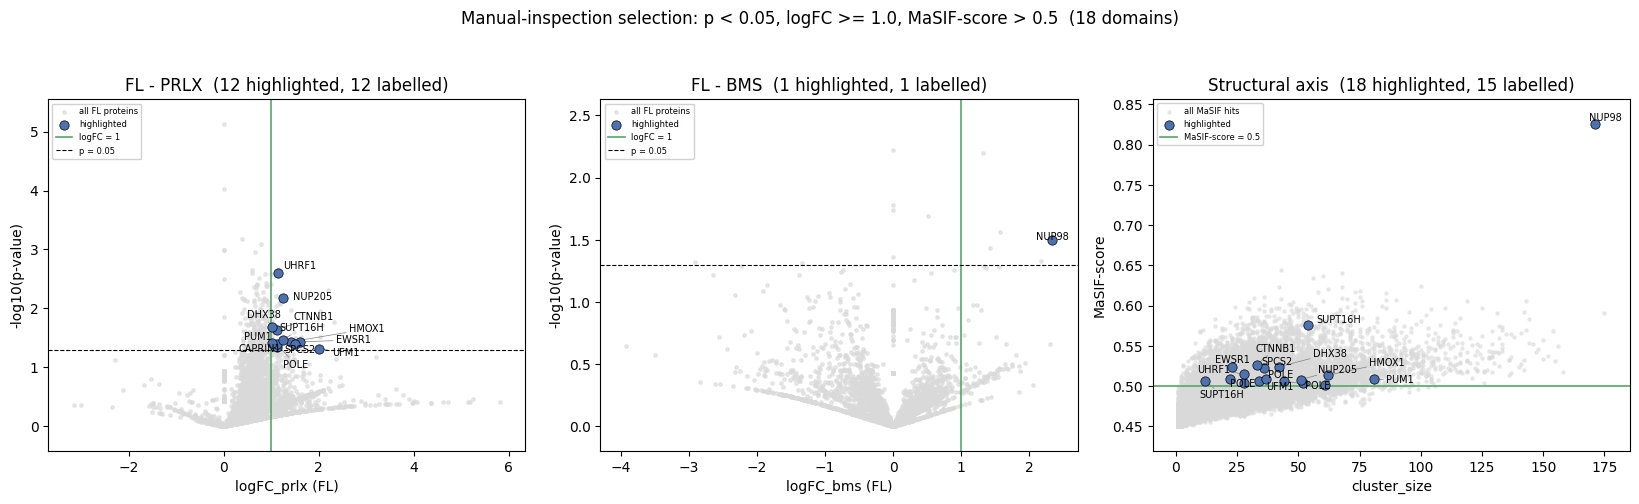

PRLX: 17 domains selected (labels capped at 15 most-enriched for readability)
BMS : 1 domains selected (labels capped at 15 most-enriched for readability)


In [27]:
# Section 7 highlight set: the manual-inspection selection, re-derived from mimicry_df because
# manual_df was concatenated with ignore_index=True and lost the original index.
manual_domains = {c: mimicry_df.index[manual_selection_mask(c)] for c in COMPOUNDS}
manual_scatter_domains = mimicry_df.index[
    manual_selection_mask("prlx") | manual_selection_mask("bms")
]

plot_candidate_panels(
    volcano_domains=manual_domains,
    scatter_domains=manual_scatter_domains,
    title=(
        f"Manual-inspection selection: p < {MANUAL_PVAL_CUTOFF}, logFC >= {MANUAL_LOGFC_CUTOFF}, "
        f"MaSIF-score > {MANUAL_MASIF_CUTOFF}  ({len(manual_scatter_domains)} domains)"
    ),
    max_labels=15,
    color="#4C72B0",
    # Section 7 has its own fixed cutoffs -- show those, not Section 5's dynamic thresholds.
    logfc_lines={c: (MANUAL_LOGFC_CUTOFF, f"logFC = {MANUAL_LOGFC_CUTOFF:g}") for c in COMPOUNDS},
    masif_line=(MANUAL_MASIF_CUTOFF, f"MaSIF-score = {MANUAL_MASIF_CUTOFF:g}"),
)
for compound in COMPOUNDS:
    print(f"{compound.upper():4s}: {len(manual_domains[compound])} domains selected "
          f"(labels capped at 15 most-enriched for readability)")

## 8. Full FL volcanoes coloured by MaSIF-score

Both FL volcanoes with the structural evidence layered directly onto them rather than shown as a separate
panel:

- **Coloured (viridis)** = a MaSIF hit, defined here as `MaSIF-score > 0.5`.
- **Small grey** = MaSIF-negative: either no matched domain at all, or a best domain scoring ≤ 0.5. Both are
  treated the same way because neither is evidence of surface mimicry.
- **Marker size is constant** — `cluster_size` is reported in the tables rather than encoded here, since
  size-varying markers made the dense centre of the volcano unreadable.

A volcano point is one IP-MS protein group, while MaSIF scores are per AlphaFold domain, so each protein is
summarised by its **best-scoring matched domain** (max `MaSIF-score`). The colour scale starts at the 0.5
hit cutoff, so it spans only scores that count as hits. Reference lines are p = 0.05 and logFC = 1.

3745 FL proteins: 1319 MaSIF hits (score > 0.5, coloured); grey = 1619 scoring <= 0.5 + 807 with no matched domain
Hit MaSIF-score range 0.500-0.826


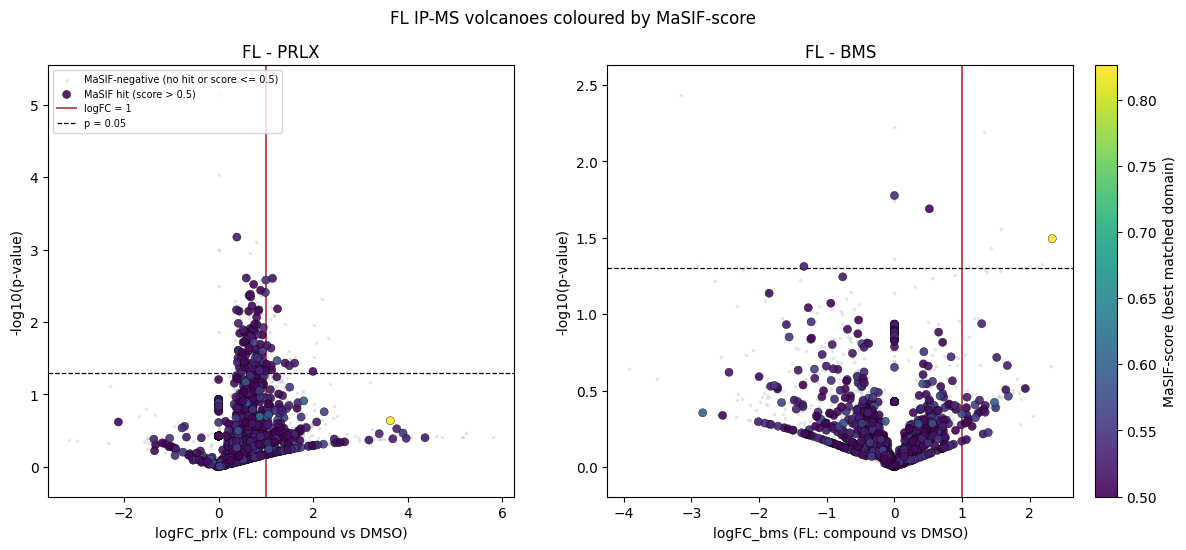

In [28]:
# A volcano point is one FL protein group, but MaSIF-score/cluster_size are per AlphaFold domain, so
# summarise each FL protein by its best-scoring matched domain (invert acc_to_fl_rows from Section 6).
fl_row_to_domains = {}
for domain_idx, accs in mimicry_df["ipms_cluster_matches"].items():
    for a in accs:
        for fl_row in acc_to_fl_rows.get(a, ()):
            fl_row_to_domains.setdefault(fl_row, []).append(domain_idx)

best_domain = {
    fl_row: mimicry_df.loc[domains, "MaSIF-score"].idxmax()
    for fl_row, domains in fl_row_to_domains.items()
}

volcano_df = fl_results[["Gene names", "logFC_prlx", "pval_prlx", "logFC_bms", "pval_bms"]].copy()
volcano_df["MaSIF-score"] = volcano_df.index.map(
    {fr: mimicry_df.loc[di, "MaSIF-score"] for fr, di in best_domain.items()}
)
volcano_df["cluster_size"] = volcano_df.index.map(
    {fr: mimicry_df.loc[di, "cluster_size"] for fr, di in best_domain.items()}
)

MASIF_HIT_CUTOFF = 0.5
volcano_df["masif_hit"] = volcano_df["MaSIF-score"] > MASIF_HIT_CUTOFF

n_hit = volcano_df["masif_hit"].sum()
n_low = ((volcano_df["MaSIF-score"] <= MASIF_HIT_CUTOFF)).sum()
n_none = volcano_df["MaSIF-score"].isna().sum()
print(
    f"{len(volcano_df)} FL proteins: {n_hit} MaSIF hits (score > {MASIF_HIT_CUTOFF}, coloured); "
    f"grey = {n_low} scoring <= {MASIF_HIT_CUTOFF} + {n_none} with no matched domain"
)
print(
    f"Hit MaSIF-score range "
    f"{volcano_df.loc[volcano_df['masif_hit'], 'MaSIF-score'].min():.3f}-"
    f"{volcano_df.loc[volcano_df['masif_hit'], 'MaSIF-score'].max():.3f}"
)


MARKER_SIZE = 34  # constant: size-varying markers made the dense centre of the volcano unreadable
norm = plt.Normalize(MASIF_HIT_CUTOFF, float(volcano_df.loc[volcano_df["masif_hit"], "MaSIF-score"].max()))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
for ax, compound in zip(axes, COMPOUNDS):
    d = volcano_df.dropna(subset=[f"logFC_{compound}", f"pval_{compound}"])
    x = d[f"logFC_{compound}"]
    y = -np.log10(d[f"pval_{compound}"])
    is_hit = d["masif_hit"]

    ax.scatter(x[~is_hit], y[~is_hit], s=6, color="#CFCFCF", alpha=0.55, linewidths=0, zorder=1,
               label=f"MaSIF-negative (no hit or score <= {MASIF_HIT_CUTOFF})")

    hit = d[is_hit]
    sc = ax.scatter(
        hit[f"logFC_{compound}"], -np.log10(hit[f"pval_{compound}"]),
        s=MARKER_SIZE, c=hit["MaSIF-score"], cmap="viridis", norm=norm,
        alpha=0.9, edgecolors="black", linewidths=0.3, zorder=3,
        label=f"MaSIF hit (score > {MASIF_HIT_CUTOFF})",
    )

    ax.axvline(MANUAL_LOGFC_CUTOFF, color="#C44E52", lw=1.4, zorder=2,
               label=f"logFC = {MANUAL_LOGFC_CUTOFF:g}")
    ax.axhline(-np.log10(0.05), color="black", ls="--", lw=0.9, zorder=2, label="p = 0.05")
    ax.set_xlabel(f"logFC_{compound} (FL: compound vs DMSO)")
    ax.set_ylabel("-log10(p-value)")
    ax.set_title(f"FL - {compound.upper()}")
    ax.margins(x=0.05, y=0.08)

axes[0].legend(fontsize=7, loc="upper left")

cbar = fig.colorbar(sc, ax=axes.ravel().tolist(), fraction=0.035, pad=0.02)
cbar.set_label("MaSIF-score (best matched domain)")

fig.suptitle("FL IP-MS volcanoes coloured by MaSIF-score", fontsize=12)
plt.show()

3745 FL proteins: 820 MaSIF hits (cluster_size >= 40, coloured); grey = 2118 below cutoff + 807 with no matched domain
Hit cluster_size range 40-171


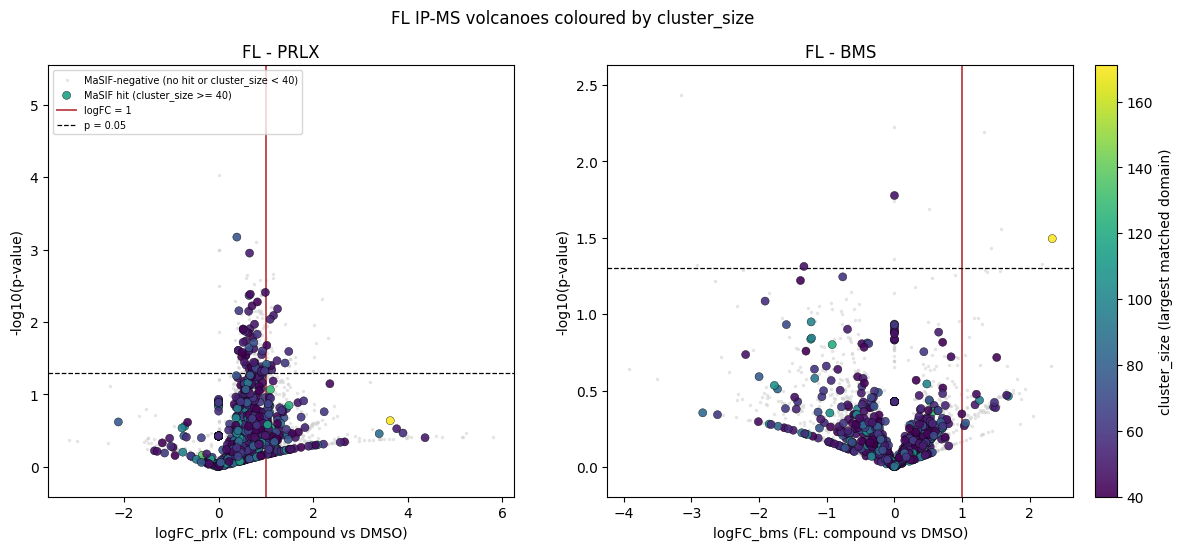

In [29]:
# Same volcanoes, but the structural evidence is now cluster_size rather than MaSIF-score.
# Hit definition here is cluster_size >= 40 (the threshold already used in the domain-library filter JSON).
# Each protein is summarised by its domain with the LARGEST cluster_size -- mirroring the max-MaSIF-score
# choice above, so the representative domain always matches the quantity being encoded.
CLUSTER_HIT_CUTOFF = 40

best_domain_by_cluster = {
    fl_row: mimicry_df.loc[domains, "cluster_size"].idxmax()
    for fl_row, domains in fl_row_to_domains.items()
}

volcano_cs = fl_results[["Gene names", "logFC_prlx", "pval_prlx", "logFC_bms", "pval_bms"]].copy()
volcano_cs["cluster_size"] = volcano_cs.index.map(
    {fr: mimicry_df.loc[di, "cluster_size"] for fr, di in best_domain_by_cluster.items()}
)
volcano_cs["MaSIF-score"] = volcano_cs.index.map(
    {fr: mimicry_df.loc[di, "MaSIF-score"] for fr, di in best_domain_by_cluster.items()}
)
volcano_cs["masif_hit"] = volcano_cs["cluster_size"] >= CLUSTER_HIT_CUTOFF

n_hit = volcano_cs["masif_hit"].sum()
n_low = (volcano_cs["cluster_size"] < CLUSTER_HIT_CUTOFF).sum()
n_none = volcano_cs["cluster_size"].isna().sum()
print(
    f"{len(volcano_cs)} FL proteins: {n_hit} MaSIF hits (cluster_size >= {CLUSTER_HIT_CUTOFF}, coloured); "
    f"grey = {n_low} below cutoff + {n_none} with no matched domain"
)
print(
    f"Hit cluster_size range "
    f"{volcano_cs.loc[volcano_cs['masif_hit'], 'cluster_size'].min():.0f}-"
    f"{volcano_cs.loc[volcano_cs['masif_hit'], 'cluster_size'].max():.0f}"
)

norm_cs = plt.Normalize(
    CLUSTER_HIT_CUTOFF, float(volcano_cs.loc[volcano_cs["masif_hit"], "cluster_size"].max())
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
for ax, compound in zip(axes, COMPOUNDS):
    d = volcano_cs.dropna(subset=[f"logFC_{compound}", f"pval_{compound}"])
    x = d[f"logFC_{compound}"]
    y = -np.log10(d[f"pval_{compound}"])
    is_hit = d["masif_hit"]

    ax.scatter(x[~is_hit], y[~is_hit], s=6, color="#CFCFCF", alpha=0.55, linewidths=0, zorder=1,
               label=f"MaSIF-negative (no hit or cluster_size < {CLUSTER_HIT_CUTOFF})")

    hit = d[is_hit]
    sc_cs = ax.scatter(
        hit[f"logFC_{compound}"], -np.log10(hit[f"pval_{compound}"]),
        s=MARKER_SIZE, c=hit["cluster_size"], cmap="viridis", norm=norm_cs,
        alpha=0.9, edgecolors="black", linewidths=0.3, zorder=3,
        label=f"MaSIF hit (cluster_size >= {CLUSTER_HIT_CUTOFF})",
    )

    ax.axvline(MANUAL_LOGFC_CUTOFF, color="#C44E52", lw=1.4, zorder=2,
               label=f"logFC = {MANUAL_LOGFC_CUTOFF:g}")
    ax.axhline(-np.log10(0.05), color="black", ls="--", lw=0.9, zorder=2, label="p = 0.05")
    ax.set_xlabel(f"logFC_{compound} (FL: compound vs DMSO)")
    ax.set_ylabel("-log10(p-value)")
    ax.set_title(f"FL - {compound.upper()}")
    ax.margins(x=0.05, y=0.08)

axes[0].legend(fontsize=7, loc="upper left")

cbar = fig.colorbar(sc_cs, ax=axes.ravel().tolist(), fraction=0.035, pad=0.02)
cbar.set_label("cluster_size (largest matched domain)")

fig.suptitle("FL IP-MS volcanoes coloured by cluster_size", fontsize=12)
plt.show()